# Nasdaq 精简前后：五模型验证结果对比

本页只读取已完成的实验，不训练模型。原方案每天 **8 个特征**；精简方案保留个股四特征及 `nasdaq_return`、`nasdaq_vol_change`，共 **6 个特征**。

先检查配置、数据指纹、日期和标签，再展示两张指标表、一张变化图及简短结论。股票名称由实验 `config.json` 读取。这里是 **2022—2023 年验证结果，不是最终测试成绩**。

六特征实验尚待运行。请先按 README 生成两个 `nasdaq_return_volume` 结果目录，再运行本页；未完成时会提示缺少结果，不复用旧图表。


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "main.py").is_file() and (p / "src/evaluate.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("请从项目目录或 notebooks 目录打开")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.evaluate import evaluate

# 显式指定：每一对依次为（原八特征实验目录，精简六特征实验目录）。
# 不扫描最新结果，不根据目录名猜测股票；换股票只需替换这两个目录。
RUN_PAIRS = [
    ("aapl_compare_all_01", "aapl_nasdaq_less_01"),
    ("tsla_compare_all_01", "tsla_nasdaq_less_01"),
]
MODELS = ["xgboost", "lightgbm", "patchtst", "lstm", "gru"]
LABELS = dict(zip(MODELS, ["XGBoost", "LightGBM", "PatchTST", "LSTM", "GRU"]))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


In [2]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))


def load_run(name):
    if not isinstance(name, str) or not name.strip() or Path(name).name != name or name in (".", ".."):
        raise ValueError("只填写 artifacts 下的实验目录名")
    folder = ROOT / "artifacts" / name
    if not folder.is_dir():
        raise FileNotFoundError(f"实验目录尚不存在：{name}。请先按 README 完成对应实验。")
    config = read_json(folder / "config.json")
    manifest = read_json(folder / "manifest.json")
    preprocessing = read_json(folder / "preprocessing.json")
    saved = read_json(folder / "metrics.json")
    predictions = pd.read_csv(folder / "predictions.csv", parse_dates=["window_start", "signal_date", "target_date"])
    if (manifest.get("status") != "complete" or manifest.get("evaluation_split") != "validation"
            or manifest.get("test_evaluated", False) or manifest.get("holdout_evaluated", False)):
        raise ValueError(f"{name}: 需要已完成的验证实验")
    if predictions.target_date.duplicated().any() or not predictions.target_date.is_monotonic_increasing:
        raise ValueError(f"{name}: 日期重复或顺序错误")
    if not np.isfinite(predictions.actual_return).all():
        raise ValueError(f"{name}: 真实收益缺失或无效")
    np.testing.assert_array_equal(predictions.actual_direction, (predictions.actual_return > 0).astype(int))
    # 从逐日预测重算指标，避免直接相信一张可能过期的汇总表。
    metrics = {}
    for model in ["zero_return", *MODELS]:
        metrics[model] = evaluate(predictions.actual_return.to_numpy(), predictions[model].to_numpy())
        for key, value in metrics[model].items():
            previous = saved[model][key]
            if value is None or previous is None:
                if value != previous:
                    raise ValueError(f"{name}: {model}/{key} 指标不一致")
            else:
                np.testing.assert_allclose(value, previous, rtol=1e-8, atol=1e-12)
    return dict(name=name, config=config, manifest=manifest, preprocessing=preprocessing,
                predictions=predictions, metrics=metrics)


pairs, records = [], []
full_features = [p + f for p in ("", "nasdaq_")
                 for f in ("return", "vol_change", "intraday_return", "range")]
for before_name, after_name in RUN_PAIRS:
    before, after = load_run(before_name), load_run(after_name)
    if before["config"].get("nasdaq_features", "all") != "all" or after["config"].get("nasdaq_features") != "return_volume":
        raise ValueError("每对实验必须按八特征、六特征顺序填写")
    configs = [{k: v for k, v in run["config"].items() if k != "nasdaq_features"} for run in (before, after)]
    if configs[0] != configs[1]:
        raise ValueError("除 Nasdaq 特征外还有配置变化，不能作为单因素对比")
    for key in ("data_sha256", "packages", "seed", "gpu", "cuda_build"):
        if before["manifest"][key] != after["manifest"][key]:
            raise ValueError(f"实验记录中的 {key} 不一致，请先核对")
    for run, expected in ((before, full_features), (after, full_features[:6])):
        if run["preprocessing"]["features"] != expected:
            raise ValueError("实际特征列表与方案不匹配")
    a, b = before["predictions"], after["predictions"]
    for key in ("window_start", "signal_date", "target_date", "actual_direction"):
        np.testing.assert_array_equal(a[key], b[key])
    np.testing.assert_allclose(a.actual_return, b.actual_return, rtol=0, atol=1e-12)
    ticker = before["config"]["ticker"]
    pairs.append((ticker, before, after))
    print(f"{ticker}: {before_name} → {after_name}")
    print(f"  检查通过：{len(a)} 个共同验证日，{a.target_date.min().date()} 至 {a.target_date.max().date()}；seed={before['config']['seed']}")
    for model in MODELS:
        old, new = before["metrics"][model], after["metrics"][model]
        row = {"stock": ticker, "model": model, "before_run": before_name, "after_run": after_name}
        for metric in ("rmse", "mae", "r2", "r2_vs_zero", "direction_accuracy", "predicted_up_rate"):
            row[metric + "_before"], row[metric + "_after"] = old[metric], new[metric]
        row["rmse_improvement_pct"] = 100 * (1 - new["rmse"] / old["rmse"])
        row["direction_change_pp"] = 100 * (new["direction_accuracy"] - old["direction_accuracy"])
        records.append(row)
comparison = pd.DataFrame(records)


AAPL: aapl_compare_all_01 → aapl_nasdaq_less_01
  检查通过：501 个共同验证日，2022-01-03 至 2023-12-29；seed=42
TSLA: tsla_compare_all_01 → tsla_nasdaq_less_01
  检查通过：501 个共同验证日，2022-01-03 至 2023-12-29；seed=42


## 1. 各股票精简前 → 精简后

- **RMSE、MAE 越低越好**，下表乘以 100，以收益百分点（pp）展示。例如 RMSE 1.82 pp 对应原始 CSV 的 0.0182。
- **R² 越高越好**，此处为普通 `r2`，不是 `r2_vs_zero`。
- **RMSE 改善率** = `(原 RMSE − 新 RMSE) / 原 RMSE × 100%`，正数表示改善。
- 方向准确率越高越好；预测上涨比例用于识别模型是否几乎总预测上涨，它本身没有“越高越好”的含义。


In [3]:
for ticker, before, after in pairs:
    rows = comparison.loc[(comparison.before_run == before["name"]) & (comparison.after_run == after["name"])]
    display(Markdown(f"### {ticker}"))
    table = pd.DataFrame(index=[LABELS[m] for m in rows.model])
    for metric, title, scale, digits in [
        ("rmse", "RMSE (pp)", 100, 4),
        ("mae", "MAE (pp)", 100, 4),
        ("r2", "R²", 1, 4),
        ("direction_accuracy", "方向准确率 (%)", 100, 2),
        ("predicted_up_rate", "预测上涨 (%)", 100, 2),
    ]:
        table[title] = [f"{r[metric + '_before'] * scale:.{digits}f} → {r[metric + '_after'] * scale:.{digits}f}"
                        for _, r in rows.iterrows()]
    table["RMSE 改善率 (%)"] = [f"{x:+.2f}" for x in rows.rmse_improvement_pct]
    display(table)
    zero_rmse = before["metrics"]["zero_return"]["rmse"] * 100
    print(f"零收益基线 RMSE：{zero_rmse:.4f} pp（两方案相同）。")


### AAPL

,RMSE (pp),MAE (pp),R²,方向准确率 (%),预测上涨 (%),RMSE 改善率 (%)
XGBoost,1.8211 → 1.8240,1.3601 → 1.3546,0.0108 → 0.0077,50.30 → 51.30,90.62 → 91.62,-0.16
LightGBM,1.8263 → 1.8250,1.3578 → 1.3614,0.0052 → 0.0066,51.10 → 49.50,94.21 → 87.03,+0.07
PatchTST,1.8717 → 1.8708,1.4000 → 1.4037,-0.0448 → -0.0438,54.49 → 51.10,70.06 → 54.69,+0.05
LSTM,1.8315 → 1.7868,1.3600 → 1.3495,-0.0004 → 0.0478,51.30 → 51.90,100.00 → 75.05,+2.44
GRU,1.8315 → 1.8277,1.3606 → 1.3628,-0.0005 → 0.0037,51.50 → 52.89,98.60 → 70.86,+0.21


零收益基线 RMSE：1.8314 pp（两方案相同）。


### TSLA

,RMSE (pp),MAE (pp),R²,方向准确率 (%),预测上涨 (%),RMSE 改善率 (%)
XGBoost,3.8220 → 3.8183,2.8754 → 2.8703,0.0047 → 0.0066,50.90 → 52.69,86.83 → 91.42,+0.09
LightGBM,3.8306 → 3.8203,2.8713 → 2.8748,0.0002 → 0.0056,53.69 → 52.50,92.81 → 85.63,+0.27
PatchTST,3.8877 → 3.9152,2.9406 → 2.9484,-0.0298 → -0.0444,53.09 → 51.30,40.32 → 58.48,-0.71
LSTM,3.8396 → 3.8413,2.8775 → 2.8785,-0.0045 → -0.0054,51.70 → 51.70,100.00 → 100.00,-0.04
GRU,3.8407 → 3.8434,2.8726 → 2.8751,-0.0051 → -0.0065,52.30 → 51.70,98.20 → 98.80,-0.07


零收益基线 RMSE：3.8310 pp（两方案相同）。


## 2. 变化一览

左图为 RMSE 的相对改善百分比；右图为方向准确率增加的百分点。两张图都是 **向右为改善、向左为下降**，但单位不同。标签按实验对排列。


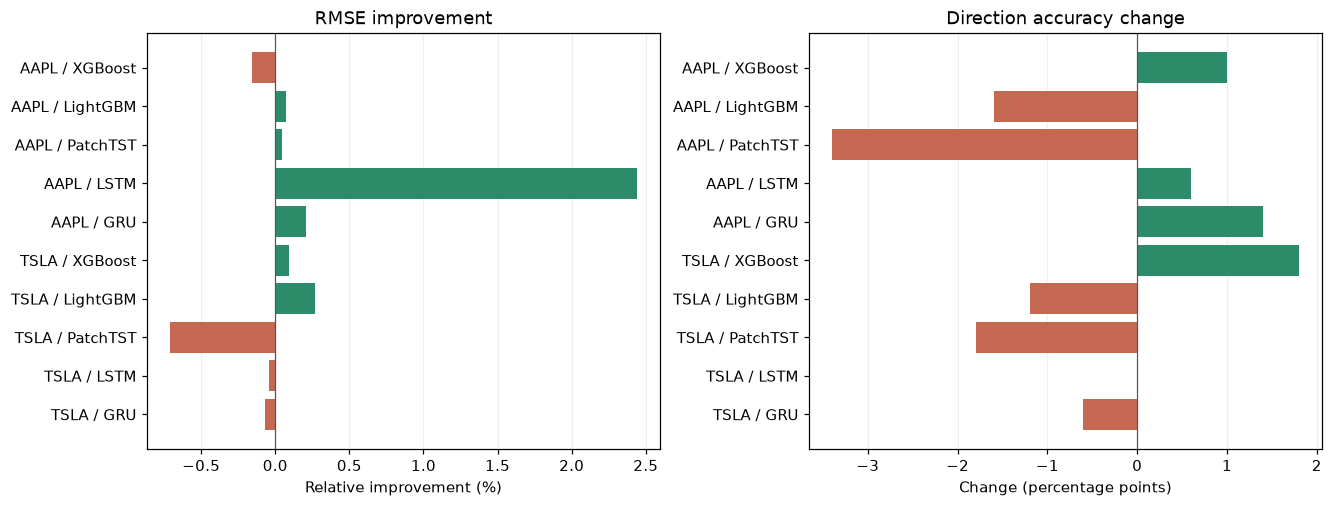

In [4]:
labels = [f"{r.stock} / {LABELS[r.model]}" for _, r in comparison.iterrows()]
fig, axes = plt.subplots(1, 2, figsize=(12, max(4, len(labels) * 0.45)), layout="constrained")
for ax, column, title, unit in zip(
    axes, ["rmse_improvement_pct", "direction_change_pp"],
    ["RMSE improvement", "Direction accuracy change"], ["Relative improvement (%)", "Change (percentage points)"]
):
    values = comparison[column].to_numpy()
    ax.barh(np.arange(len(labels)), values, color=["#2c8c69" if v > 0 else "#c56851" if v < 0 else "#888888" for v in values])
    ax.set_yticks(np.arange(len(labels)), labels)
    ax.invert_yaxis()
    ax.axvline(0, color="#555555", linewidth=0.8)
    ax.set(title=title, xlabel=unit)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()


## 3. 简短结论

以下结论按所选结果自动生成，以主要任务的 RMSE 为主。一次固定种子的验证比较不能证明稳定改善，也不能证明某个 Nasdaq 字段一定无用；输入维度变化也会改变部分模型的结构和随机训练过程。


In [5]:
for ticker, before, after in pairs:
    rows = comparison.loc[(comparison.before_run == before["name"]) & (comparison.after_run == after["name"])]
    better = rows.loc[rows.rmse_improvement_pct > 0]
    best = rows.loc[rows.rmse_after.idxmin()]
    direction_better = int((rows.direction_change_pp > 0).sum())
    beats_zero = rows.loc[rows.r2_vs_zero_after > 0, "model"].map(LABELS).tolist()
    display(Markdown(
        f"**{ticker}**：{len(better)}/5 个模型 RMSE 下降，{direction_better}/5 个模型方向准确率提高。"
        f"精简后 RMSE 最低的是 **{LABELS[best.model]}**（{best.rmse_after * 100:.4f} pp）。"
        f"精简后在 RMSE 上优于零收益基线的模型：{'、'.join(beats_zero) or '无'}。"
    ))
    for _, r in rows.iterrows():
        if r.predicted_up_rate_after >= 0.95:
            print(f"  注意 {LABELS[r.model]}：精简后 {r.predicted_up_rate_after:.2%} 的日期预测上涨，方向表现需结合多数方向基线理解。")
print("结论只针对本次验证集；没有使用最终测试集，没有重新训练。")


**AAPL**：4/5 个模型 RMSE 下降，3/5 个模型方向准确率提高。精简后 RMSE 最低的是 **LSTM**（1.7868 pp）。精简后在 RMSE 上优于零收益基线的模型：XGBoost、LightGBM、LSTM、GRU。

**TSLA**：2/5 个模型 RMSE 下降，1/5 个模型方向准确率提高。精简后 RMSE 最低的是 **XGBoost**（3.8183 pp）。精简后在 RMSE 上优于零收益基线的模型：XGBoost、LightGBM。

  注意 LSTM：精简后 100.00% 的日期预测上涨，方向表现需结合多数方向基线理解。
  注意 GRU：精简后 98.80% 的日期预测上涨，方向表现需结合多数方向基线理解。
结论只针对本次验证集；没有使用最终测试集，没有重新训练。
